# 01. Agent foundations

## Problem

An engineer asks who approves a production restore. Northstar must consult policy, correlate the tool result with its request, and stop within an enforced budget.

## Learning objectives

Explain next-token inference and the model/agent/harness/runtime distinction; validate structured actions; implement a bounded loop; compare it with a real LangGraph run.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## LLM inference from first principles

An LLM generates tokens based on a sequence of preceding tokens.

At a simplified level:

$$ P(t_{n+1}\mid t_1,t_2,\ldots,t_n) $$

The model estimates a probability distribution for the next token given the current context.

**Tokens are not the same as words.** A token may represent a word, part of a word, punctuation, or another encoded unit. Different model families use different tokenizers.

The model processes input tokens through a transformer. Attention allows representations at one position to incorporate information from other positions. The model then produces a distribution over possible next tokens.

Token selection can be more or less deterministic depending on decoding settings.

```
Input:
Who approves a production restore?

Candidate next-token continuations:
"The"
"According"
"I"
```

The model does not automatically query Northstar's policy database. Without evidence, a fluent continuation may simply be a plausible guess.

### **Context windows and output limits**

A context window bounds how much tokenized information the model can process in an invocation. It must accommodate model-visible instructions, history, tool schemas, and other supplied content, subject to the provider's exact accounting rules.

Output generation has its own configurable or model-specific limits.

A hypothetical planning budget could be:

```
Available model context:   32,000 tokens
System/tool instructions:   3,000
Conversation and state:     5,000
Retrieved evidence:        12,000
Reserved output:            4,000
Safety headroom:            8,000
```

These numbers are **illustrative**, not Ollama settings or a benchmark.

A large context is not equivalent to persistent memory. Information disappears from the model's current view when an application no longer supplies it. The application must decide what to retain, retrieve, or summarize.

## Model, agent, harness, runtime

These terms describe different responsibilities.

| Component    | What it does                                     | Northstar example                            |
| ------------ | ------------------------------------------------ | -------------------------------------------- |
| Model        | Generates a response or structured action        | Ollama-hosted language model                 |
| Agent        | Uses observations to select subsequent actions   | Search, inspect result, search again, answer |
| Harness      | Supplies instructions, capabilities and policies | Deep Agents                                  |
| Runtime      | Executes, tracks and coordinates operations      | LangGraph                                    |
| Tool         | Performs an action outside inference             | `search_knowledge`                           |
| Checkpointer | Persists execution state                         | SQLite checkpoint backend                    |

An agent is not just a model with a long system prompt.

The essential difference is **the feedback loop**.

The model requests an action. The application actually executes it.

This distinction is essential to debugging, security, and reliability.

## Worked example: one policy question

The model emits a tool request:

```
{
  "id": "call_001",
  "name": "search_knowledge",
  "arguments": {
    "query": "production restore approval",
    "top_k": 3
  }
}
```

The application validates it and searches Northstar.

The result:

```
{
  "call_id": "call_001",
  "status": "success",
  "hits": [
    {
      "id": "BKP-7#p12",
      "revision": "4",
      "excerpt": "Production restores require approval from the Database Operations Lead."
    }
  ]
}
```

The model receives that result and generates:

> The Database Operations Lead must approve a production restore, according to BKP-7 revision 4.

Notice that the tool-call ID establishes which result belongs to which request. This becomes important when an agent issues multiple calls or executes work concurrently.

## Choosing between RAG, workflows, and agents

A direct RAG implementation could simply retrieve relevant documents and call the model once.

A deterministic workflow might perform two specified searches, validate the results, and generate a comparison.

A single agent may decide to reformulate queries after seeing incomplete evidence.

Delegated agents can research independent topics in separate contexts.

| Problem                                            | Preferred starting point |
| -------------------------------------------------- | ------------------------ |
| Find one restore approver                          | Direct RAG               |
| Compare two explicitly named policies              | Deterministic workflow   |
| Discover relevant policies and resolve uncertainty | Bounded single agent     |
| Investigate many independent policy domains        | Consider delegation      |

Agent complexity is justified by uncertainty in the required sequence of work—not by the presence of an LLM.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

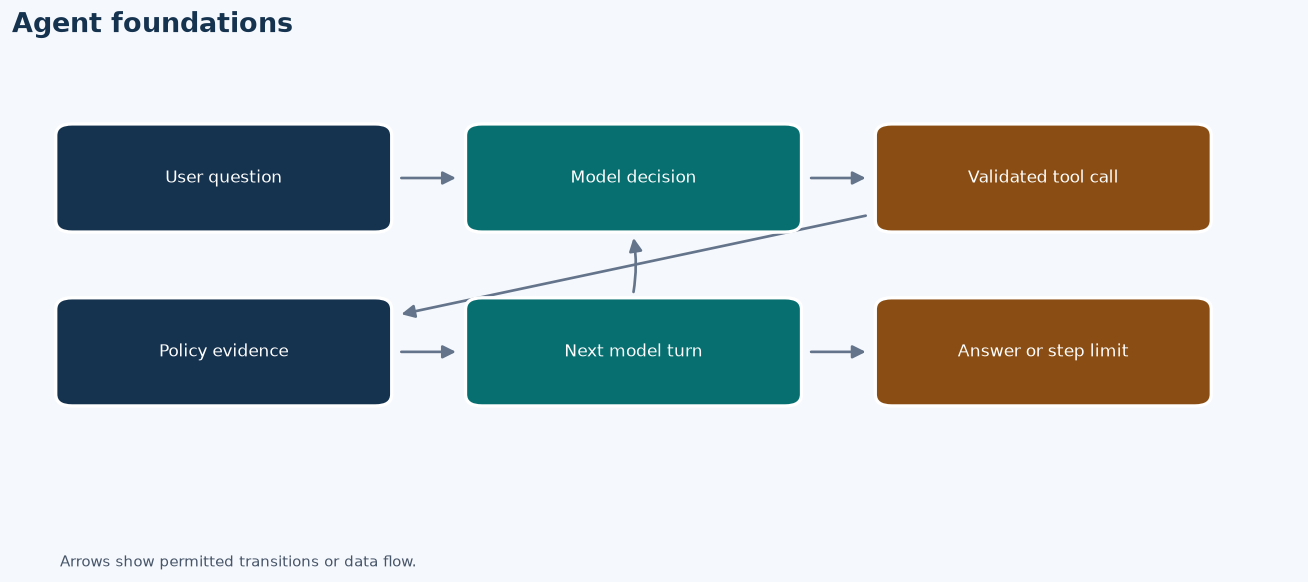

In [2]:
display(diagram('Agent foundations', ['User question', 'Model decision', 'Validated tool call', 'Policy evidence', 'Next model turn', 'Answer or step limit'], [(0, 1), (1, 2), (2, 3), (3, 4), (4, 1), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import json
from deep_agent_lab.foundations import ToolCall, FinalAnswer, SearchArgs, StepLimit
from deep_agent_lab.knowledge import fixture_search

# Write the control flow here before delegating it to a framework.
def small_loop(decide, question, max_steps=4):
    messages = [{"role": "user", "content": question}]
    seen = set()
    for step in range(max_steps):
        action = decide(messages)
        if isinstance(action, FinalAnswer):
            return action.text, messages
        assert action.name == "search_knowledge" and action.id not in seen
        args = SearchArgs.model_validate(action.arguments)  # Runtime validation, like Zod.
        seen.add(action.id)
        messages.append({"role": "assistant", "id": action.id, "name": action.name})
        hits = [row.model_dump() for row in fixture_search(args.query, args.top_k)]
        messages.append({"role": "tool", "tool_call_id": action.id, "content": json.dumps(hits)})
    raise StepLimit("Decision budget exhausted")

def scripted_decision(messages):
    if messages[-1]["role"] == "user":
        return ToolCall("search-1", "search_knowledge", {"query": messages[-1]["content"]})
    hits = json.loads(messages[-1]["content"])
    return FinalAnswer(hits[0]["excerpt"] if hits else "Evidence gap")

answer, trajectory = small_loop(scripted_decision, "production restore")
assert "database operations lead" in answer
assert trajectory[1]["id"] == trajectory[2]["tool_call_id"]
print(answer)
print([(event["role"], event.get("tool_call_id")) for event in trajectory])

The database operations lead approves production restores. Restore into an isolated database first and validate the requested records before touching production. After restoration, designated operators must verify service health and record the validation result.
[('user', None), ('assistant', None), ('tool', 'search-1')]


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
with open_checkpointer(settings) as checkpoints:
    service = AgentService(settings, checkpoints)
    try:
        result = service.run(RunRequest(prompt="Who approves a production restore?"))
        snapshot = service.agent.get_state(service.config(result.thread_id))
    finally:
        service.close()
assert result.steps == ["search_knowledge"]
assert result.evidence[0].citation in result.answer
print(result.answer)
print([type(message).__name__ for message in snapshot.values["messages"]])

## Findings

- The database operations lead approves production restores. Restore into an isolated database first and validate the requested records before touching production. After restoration, designated operators must verify service health and record the validation result. [[bfa9b1f0bc3e]]

## Next steps

Verify the source excerpts.
['HumanMessage', 'AIMessage', 'ToolMessage', 'AIMessage']


## Code walkthrough

The scripted decision is explicitly a fixture: it performs no neural inference. It still returns the same two kinds of action a live model would request. Pydantic validates at runtime, whereas Python type hints alone do not. The real factory in `agent.py` constructs Deep Agents on LangGraph; its checkpoint contains HumanMessage, AIMessage and ToolMessage objects. The tool-call ID pairs an observation with its request. A workflow fixes the order in code; an agent can select the next tool from observations.

## Interactive experiments

Change the question and the decision budget. A model must have a remaining decision slot after receiving evidence to produce its final answer.

In [5]:
for question in ["SEV-1 incident", "ZEPHYR-99"]:
    text, events = small_loop(scripted_decision, question)
    print(question, "=>", text[:110])
assert small_loop(scripted_decision, "ZEPHYR-99")[0] == "Evidence gap"

SEV-1 incident => For a SEV-1 incident, the on-call engineer immediately pages the incident commander and opens an incident chan
ZEPHYR-99 => Evidence gap


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
try:
    small_loop(lambda messages: ToolCall(str(len(messages)), "search_knowledge", {"query": "restore"}),
               "restore", max_steps=2)
except StepLimit as error:
    print("Expected orchestration failure:", error)
else:
    raise AssertionError("An endless model must hit the application budget")

Expected orchestration failure: Decision budget exhausted


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
from deep_agent_lab.foundations import agent_loop
text, events = agent_loop(scripted_decision,
                         lambda q,k: [row.model_dump() for row in fixture_search(q,k)], "restore")
assert "database operations lead" in text and events[-1]["role"] == "assistant"
print("Verified: result-dependent answer, correlated tool ID, bounded termination.")

Verified: result-dependent answer, correlated tool ID, bounded termination.


## Exercise

Implement a decision function that abstains after an empty result and uses the exact citation after a successful result. Explain why a JSON-only one-shot call is structured generation but does not by itself implement an agent loop.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
def cited_decision(messages):
    if messages[-1]["role"] == "user":
        return ToolCall("cited-1", "search_knowledge", {"query": messages[-1]["content"]})
    rows = json.loads(messages[-1]["content"])
    return FinalAnswer(f"{rows[0]['excerpt']} {rows[0]['citation']}" if rows else "Evidence gap")
assert "[[" in small_loop(cited_decision, "restore")[0]
assert small_loop(cited_decision, "ZEPHYR-99")[0] == "Evidence gap"

## Trade-offs and further reading

A single policy lookup often needs direct RAG rather than an agent. Use the feedback loop when the next search depends on the previous observation. Temperature zero reduces sampling variation but does not establish factual correctness.

[Primary source 1](https://www.anthropic.com/research/building-effective-agents) · [Primary source 2](https://docs.langchain.com/oss/python/deepagents/overview)

## Optional live integration

Install Ollama and initialize/ingest the configured PostgreSQL/OpenSearch corpus as described in `docs/operations.md`. Set RUN_LIVE only when those dependencies are available. This cell is skipped in offline verification. A successful live run still requires claim-level review; token and cost measurements are only meaningful when the provider reports them.

In [9]:
RUN_LIVE = False
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live")
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()

In [10]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
